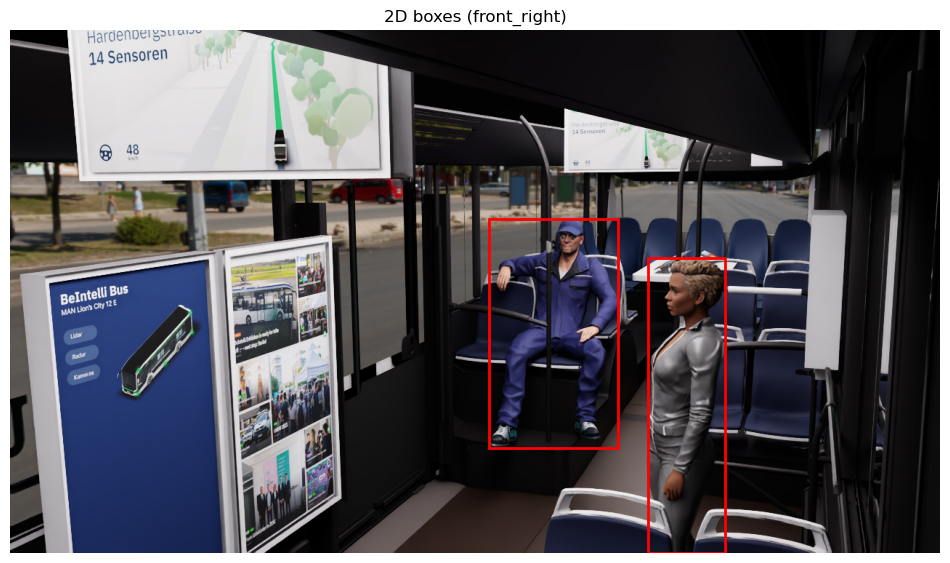

In [1]:
from synth_ndf_dataset import Dataset
import matplotlib.pyplot as plt

ds = Dataset("../data/20260604T105944Z")
FRAME_IDX = 120


sample = ds[FRAME_IDX]

perspective = "front_right"

img = sample.camera[perspective].image


plt.figure(figsize=(12, 8))
plt.imshow(img)
for bbox in sample.camera[perspective].bbox_2d:
    x0, y0, x1, y1 = bbox.to_array()
    plt.gca().add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                       edgecolor="red", facecolor="none", linewidth=2))
plt.title(f"2D boxes ({perspective})")
plt.axis("off")
plt.show()

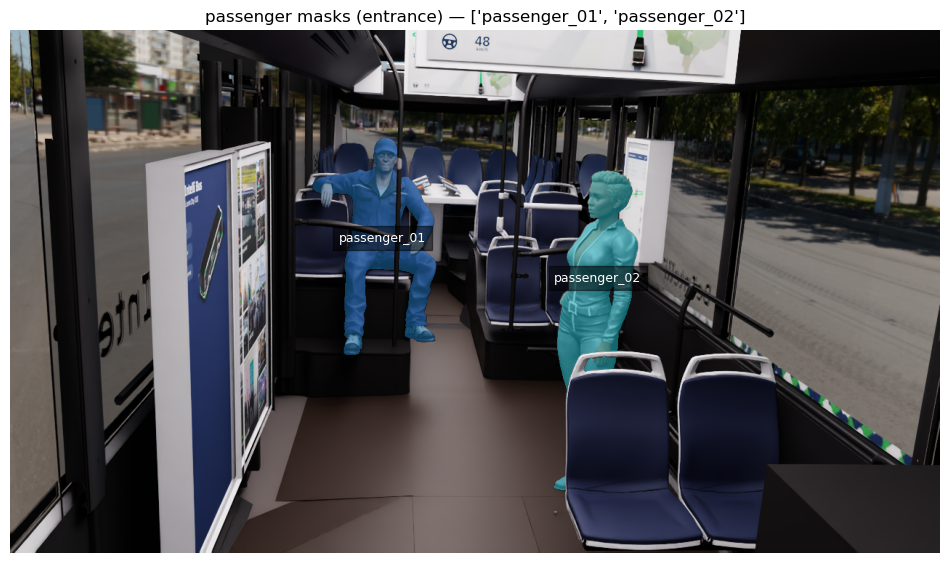

seg colour -> prim: {(255, 0, 0): '/World/Passengers/passenger_01', (0, 255, 0): '/World/Passengers/passenger_02'}


In [2]:
import numpy as np

cam_name = "entrance"

cs = sample.camera[cam_name]
plt.figure(figsize=(12, 8))
plt.imshow(cs.image)
colors = plt.cm.tab10(np.linspace(0, 1, max(len(cs.person_masks), 1)))
for (actor, mask), col in zip(sorted(cs.person_masks.items()), colors):
    overlay = np.zeros((*mask.shape, 4))
    overlay[mask] = (*col[:3], 0.5)
    plt.imshow(overlay)
    ys, xs = np.where(mask)
    if len(xs):
        plt.text(xs.mean(), ys.mean(), actor, color="white",
                 ha="center", fontsize=9, bbox=dict(facecolor="black", alpha=0.5))
plt.title(f"passenger masks ({cam_name}) — {list(cs.person_masks)}")
plt.axis("off")
plt.show()

print("seg colour -> prim:", cs.seg_mapping)


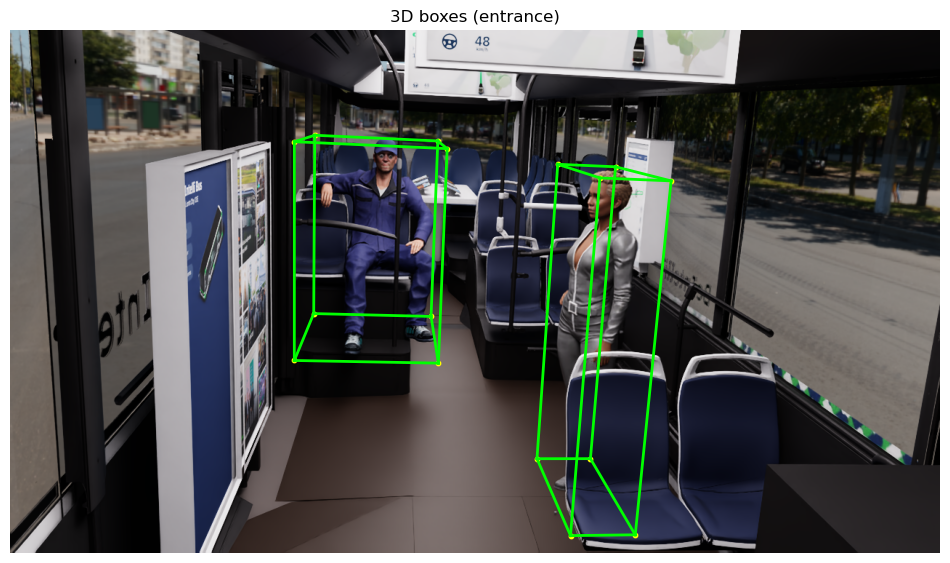

In [3]:
cam_name = "entrance"
cam = next(c for c in ds.cameras if c.camera_name == cam_name)
K, world_to_cam = cam.K.reshape(3, 3), cam.world_to_camera


def project_points(pts_world, camera_intrinsics, world_to_camera):
    pts_h = np.concatenate([pts_world, np.ones((pts_world.shape[0], 1))], axis=1)
    cam_pts = (world_to_camera @ pts_h.T).T[:, :3]      # p_cam = M @ p_world (OpenCV)
    z = cam_pts[:, 2].copy()
    z[z == 0] = 1e-6
    uv = (camera_intrinsics @ cam_pts.T).T
    uv = uv[:, :2] / uv[:, 2:3]
    return uv, cam_pts[:, 2]


edges = [(0, 1), (0, 2), (0, 4), (1, 3), (1, 5), (2, 3),
         (2, 6), (3, 7), (4, 5), (4, 6), (5, 7), (6, 7)]

img = sample.camera[cam_name].image
plt.figure(figsize=(12, 8))
plt.imshow(img)
ax = plt.gca()
for b in sample.world.bbox_3d:
    uv, depth = project_points(b.world_corners(), K, world_to_cam)
    for a, c in edges:
        if depth[a] > 0 and depth[c] > 0:
            ax.plot([uv[a, 0], uv[c, 0]], [uv[a, 1], uv[c, 1]], color="lime", linewidth=2)
    front = depth > 0
    ax.scatter(uv[front, 0], uv[front, 1], c="yellow", s=10)
plt.title(f"3D boxes ({cam_name})")
plt.axis("off")
plt.show()


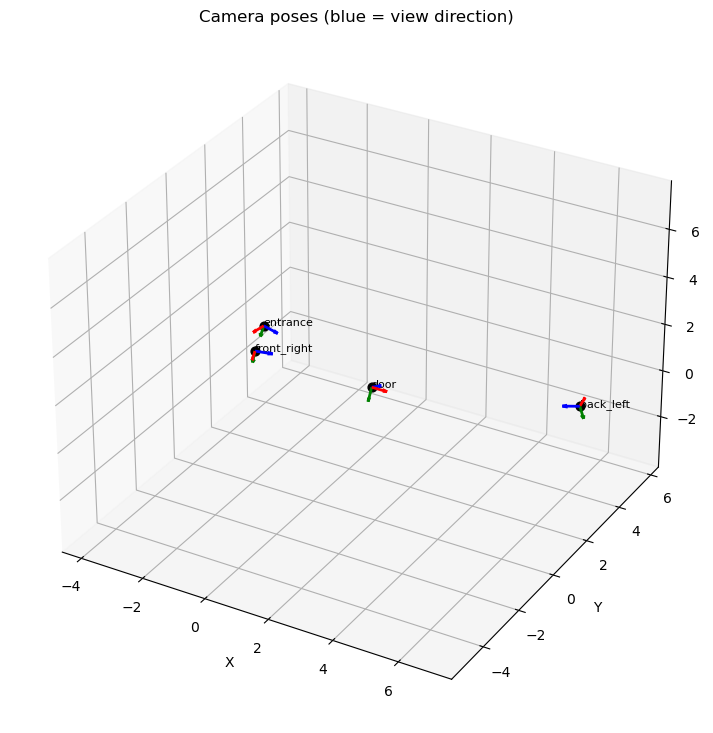

In [4]:

fig = plt.figure(figsize=(9, 9))
ax3d = fig.add_subplot(111, projection="3d")
all_origins = []
for cam in ds.cameras:
    cam_to_world = np.linalg.inv(cam.world_to_camera)   # invert: world<-camera
    origin = cam_to_world[:3, 3]
    R = cam_to_world[:3, :3]
    all_origins.append(origin)
    ax3d.scatter(*origin, c="k", s=40)
    ax3d.text(*origin, cam.camera_name, fontsize=8)
    for axis_idx, col in zip(range(3), ("r", "g", "b")):   # x,y,z = r,g,b; z=view dir
        ax3d.quiver(*origin, *(R[:, axis_idx] * 0.5), color=col, linewidth=2)
all_origins = np.array(all_origins)
c = all_origins.mean(0)
r = np.ptp(all_origins, 0).max() / 2 + 1.0
for setter, ci in zip((ax3d.set_xlim, ax3d.set_ylim, ax3d.set_zlim), c):
    setter(ci - r, ci + r)
ax3d.set_xlabel("X"); ax3d.set_ylabel("Y"); ax3d.set_zlabel("Z")
ax3d.set_title("Camera poses (blue = view direction)")
plt.show()


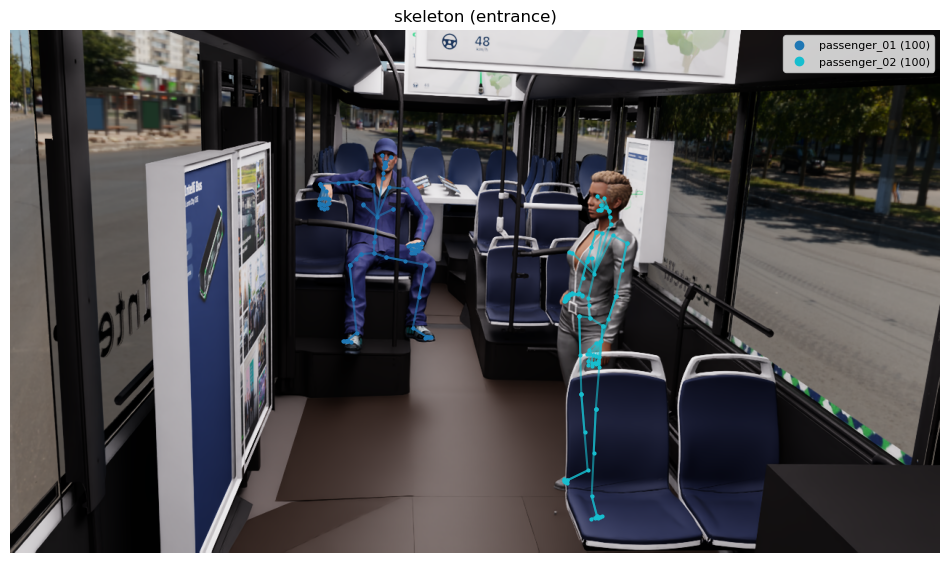

In [5]:
cam_name = "entrance"
cam = next(c for c in ds.cameras if c.camera_name == cam_name)

img = sample.camera[cam_name].image

plt.figure(figsize=(12, 8))
plt.imshow(img)
ax = plt.gca()

colors = plt.cm.tab10(np.linspace(0, 1, max(len(sample.world.skeletons), 1)))

for actor, col in zip(sample.world.skeletons, colors):
    joints = actor.joints

    uv = {}
    for j in joints:
        w = j.world
        i = j.index
        if w is None:
            continue
        if j.name == "RL_BoneRoot":
            continue
        uv_xy, z = cam.project(w)
        if z[0] > 0:
            uv[i] = uv_xy[0]
    # edges
    for i, j in actor.connections():
        p = actor.get_parent(j)
        if p is not None and p.index in uv and j in uv:
            ax.plot(
                [uv[p.index][0], uv[j][0]],
                [uv[p.index][1], uv[j][1]],
                color=col,
                lw=1.5,
                alpha=0.6,
                zorder=2,
            )

    # points
    if uv:
        pts = np.array(list(uv.values()))
        ax.scatter(pts[:, 0], pts[:, 1], color=col, s=4, zorder=3)

    label = actor.passenger_key()
    ax.scatter([], [], color=col, label=f"{label} ({len(uv)})")

ax.legend(loc="upper right", fontsize=8)

plt.axis("off")
plt.title(f"skeleton ({cam_name})")
plt.show()

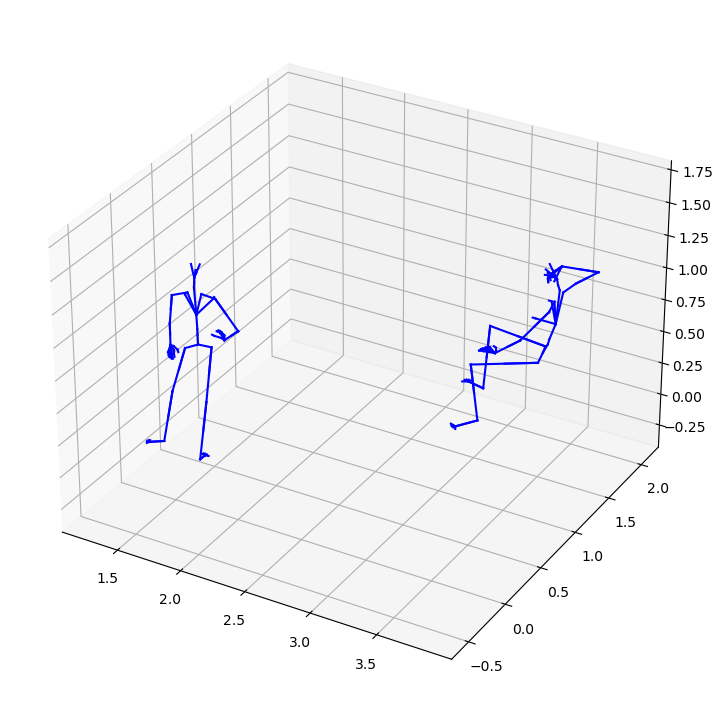

In [6]:
fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")
for skeleton in sample.world.skeletons:
    joints = skeleton.joints
    for i, j in skeleton.connections():
        p = skeleton.get_parent(j)
        w1 = p.world if p is not None else None
        w2 = skeleton.joint(j).world
        if w1 is not None and w2 is not None:
            ax.plot([w1[0], w2[0]], [w1[1], w2[1]], [w1[2], w2[2]], color="blue")
plt.axis("equal")
plt.show()

shape=(720, 1280)  dtype=float32  meters/unit=1.0
finite pixels = 921166 / 921600  (99.95%)
inf=434  nan=0
depth (m): min=1.471  median=3.248  mean=3.858  p99=9.950  max=10.329


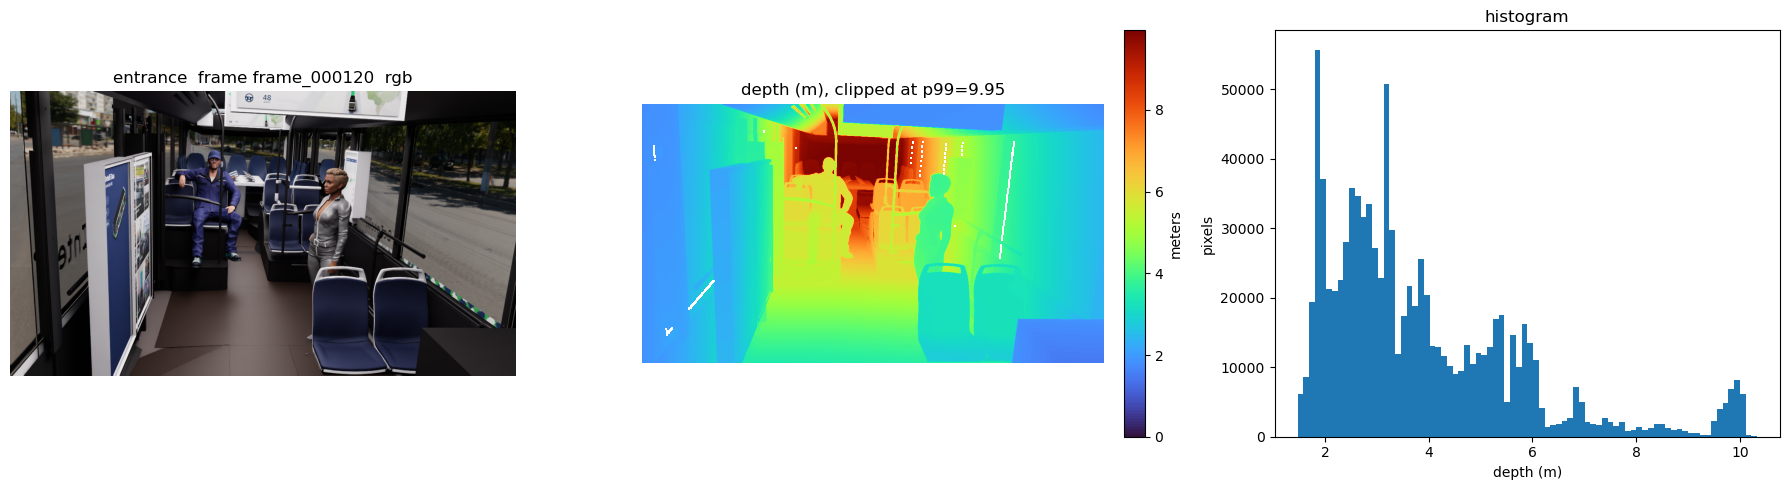

In [7]:
import numpy as np
import matplotlib.pyplot as plt


CAMERA = "entrance"

cs = ds[FRAME_IDX].camera[CAMERA]
depth = cs.depth
assert depth is not None, "No depth file. Add 'depth' to capture.formats."

mpu = float(ds.metadata.get("stage", {}).get("meters_per_unit", 1.0))
finite = np.isfinite(depth) & (depth > 0) & (depth < 1e6)
valid_m = depth[finite] * mpu

print(f"shape={depth.shape}  dtype={depth.dtype}  meters/unit={mpu}")
print(f"finite pixels = {finite.sum()} / {finite.size}  ({100*finite.mean():.2f}%)")
print(f"inf={np.isinf(depth).sum()}  nan={np.isnan(depth).sum()}")
if valid_m.size:
    print(f"depth (m): min={valid_m.min():.3f}  median={np.median(valid_m):.3f}  "
          f"mean={valid_m.mean():.3f}  p99={np.percentile(valid_m,99):.3f}  max={valid_m.max():.3f}")

vmax = float(np.percentile(valid_m, 99)) if valid_m.size else 1.0
depth_viz = np.where(finite, depth * mpu, np.nan)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(cs.image)
ax[0].set_title(f"{CAMERA}  frame {ds.samples_ids[FRAME_IDX]}  rgb")
ax[0].axis("off")
im = ax[1].imshow(depth_viz, cmap="turbo", vmin=0.0, vmax=vmax)
ax[1].set_title(f"depth (m), clipped at p99={vmax:.2f}")
ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04, label="meters")
ax[2].hist(valid_m, bins=80)
ax[2].set_xlabel("depth (m)")
ax[2].set_ylabel("pixels")
ax[2].set_title("histogram")
plt.tight_layout()
plt.show()

/tmp/ipykernel_24142/1239629812.py:12: RuntimeWarning: invalid value encountered in multiply
  ys = (ys - intrinsics[1, 2]) * depth / intrinsics[1, 1]


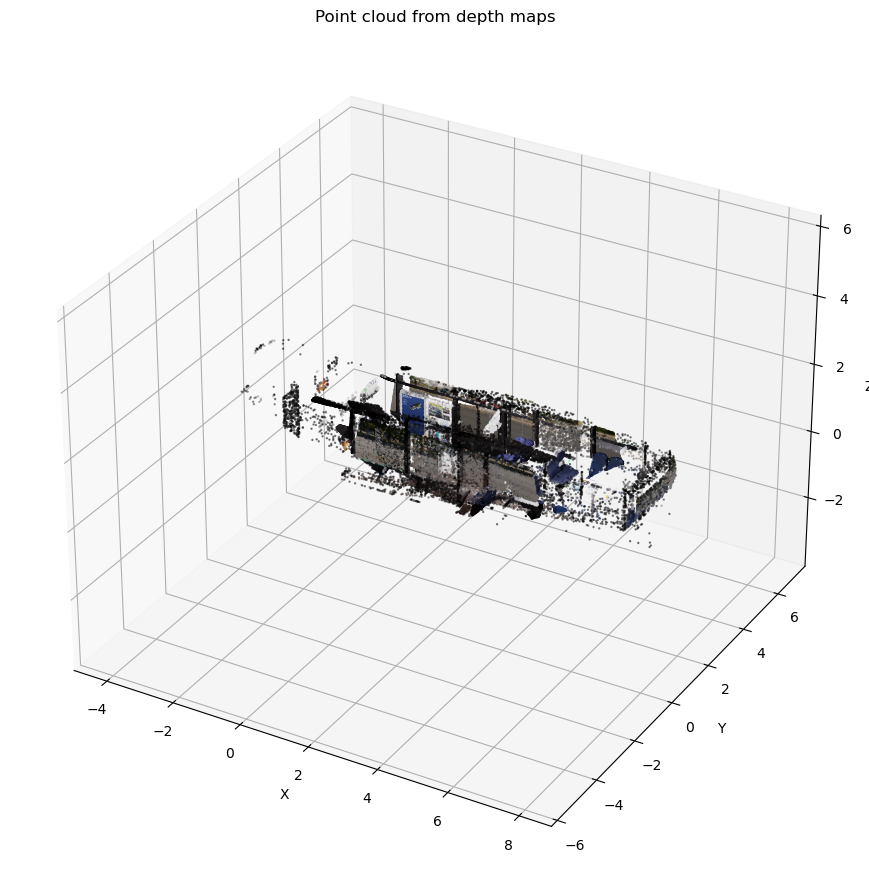

In [8]:
cam_points = []
point_colors = []
for cam in ds.cameras:
    depth = ds[FRAME_IDX].camera[cam.camera_name].depth.copy()
    if depth is None:
        continue
    mpu = float(ds.metadata.get("stage", {}).get("meters_per_unit", 1.0))
    h, w = depth.shape
    ys, xs = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    intrinsics = cam.K.reshape(3, 3)
    xs = (xs - intrinsics[0, 2]) * depth / intrinsics[0, 0]
    ys = (ys - intrinsics[1, 2]) * depth / intrinsics[1, 1]
    points_cam = np.stack([xs, ys, depth], axis=-1) * mpu
    cam_to_world = np.linalg.inv(cam.world_to_camera)   # invert: world<-camera
    points_world = (cam_to_world @ np.concatenate([points_cam, np.ones((h, w, 1))], axis=2).reshape(-1, 4).T).T[:, :3]
    cam_points.append(points_world)
    point_colors.append(ds[FRAME_IDX].camera[cam.camera_name].image.reshape(-1, 3) / 255.0)
cam_points = np.concatenate(cam_points, axis=0)
point_colors = np.concatenate(point_colors, axis=0)
subsample = np.random.choice(len(cam_points), size=min(100000, len(cam_points)), replace=False)
cam_points = cam_points[subsample]
point_colors = point_colors[subsample]

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(cam_points[:, 0], cam_points[:, 1], cam_points[:, 2], c=point_colors, s=0.5, alpha=0.5)
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_title("Point cloud from depth maps")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

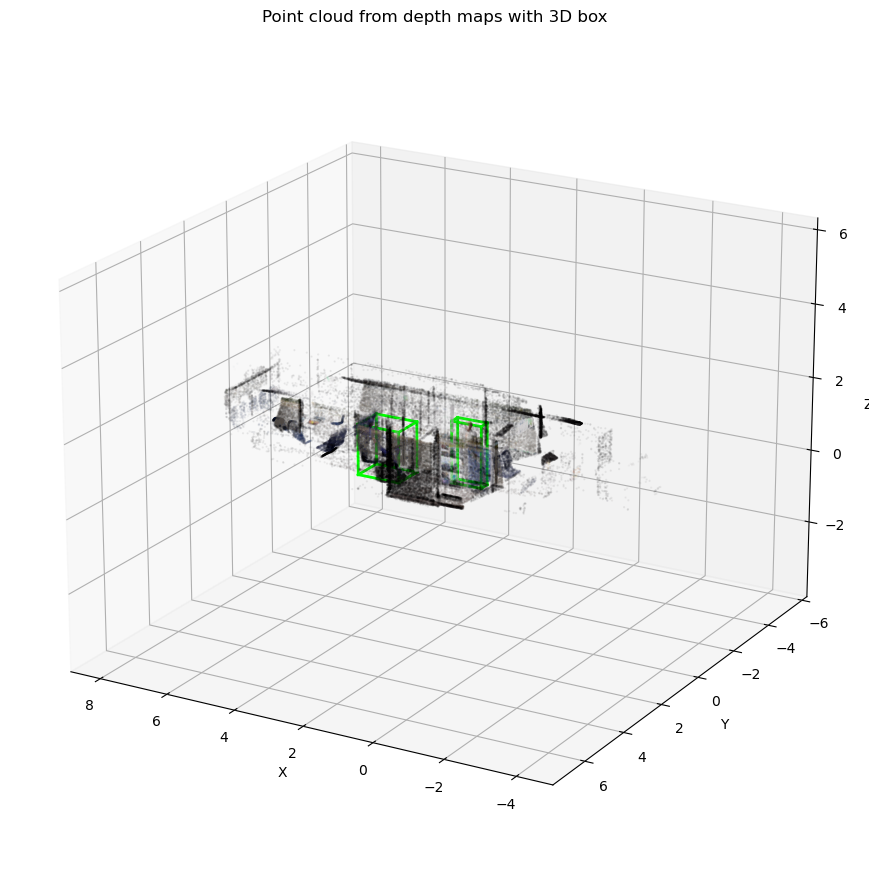

In [9]:
fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection="3d")

for bbox in sample.world.bbox_3d:
    corners = bbox.world_corners()
    for a, c in edges:
        ax.plot([corners[a, 0], corners[c, 0]], [corners[a, 1], corners[c, 1]], [corners[a, 2], corners[c, 2]], color="lime", linewidth=2)

ax.scatter(cam_points[:, 0], cam_points[:, 1], cam_points[:, 2], c=point_colors, s=0.5, alpha=0.05)
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_title("Point cloud from depth maps with 3D box")
ax.set_aspect("equal")
ax.view_init(elev=20, azim=120)
plt.tight_layout()
plt.show()